# 作业1
0927
- 使用 Python + NumPy，不直接调用 sklearn 线性回归模型，编程实现线性回归（解析解 + 梯度下降）；
- 数据集：网上数据集或者自己构造带噪声的合成数据集。
- 训练过程：
    - 绘制损失、模型参数随迭代次数的变化曲线；调学习率观察收敛变化；
    - 可视化：训练散点 + 拟合直线或平面（单变量、2变量时）

# 数据集

In [4]:
# 加载清洗数据集
import sys, pathlib
sys.path.append( str (pathlib.Path.cwd().parent))

from my_datasets.iris_utils import load_iris_ready
x_train, x_test, y_train, y_test, scaler = load_iris_ready()

display(x_train)
display(y_train)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
30,-1.192531,0.035465,-1.143600,-1.222275
31,-0.454691,0.701825,-1.201142,-0.959728
80,-0.331718,-1.519376,0.122339,-0.040816
88,-0.208745,-0.186656,0.294967,0.221730
55,-0.085771,-0.630896,0.525137,0.221730
...,...,...,...,...
102,1.635854,-0.186656,1.330734,1.271916
100,0.652068,0.479705,1.388277,1.797009
44,-0.823611,1.590305,-0.970972,-0.959728
132,0.775042,-0.630896,1.158106,1.403189


30         setosa
31         setosa
80     versicolor
88     versicolor
55     versicolor
          ...    
102     virginica
100     virginica
44         setosa
132     virginica
117     virginica
Name: species, Length: 119, dtype: object

# 单变量

## 解析解法
![image.png](./第二章%20线性模型_pages/单变量-解析解法/page_014.png)

In [7]:
# 单变量线性回归 —— 解析解（严格按课件《第二章 线性模型》单变量-解析解法推导实现）
# 损失函数  E(w,b) = 1/(2m) * Σ (y_i - w*x_i - b)^2                （课件 page 7）
# 公式(3.7) w = Σ y_i*(x_i - x̄) / [Σ x_i² - (1/m)*(Σ x_i)²]        （课件 page 14）
# 公式(3.8) b = (1/m) * Σ (y_i - w*x_i)                            （课件 page 14）
# 计算顺序：先由 (3.7) 求 w，再代回 (3.8) 求 b
import numpy as np

# ---------- 1 准备单变量数据 ----------
# 单变量：只用一个特征 x = petal length (cm)（已标准化）
# 目标值 y 用 y_train：品种名是字符串，线性回归需要数字，映射回 sklearn 原始编号
#   setosa=0, versicolor=1, virginica=2
x = x_train['petal length (cm)'].to_numpy()     # 形状 (m,)
y = y_train.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()  # 形状 (m,)
m = len(x)                                      # 训练样本数

# ---------- 2 公式(3.7) 求 w ----------
x_bar = x.sum() / m                             # x̄：x 的均值
w = (y * (x - x_bar)).sum() / (np.sum(x**2) - x.sum()**2 / m)

# ---------- 3 公式(3.8) 求 b ----------
b = (y - w * x).sum() / m

# ---------- 4 用损失函数 E(w,b) 验证拟合效果 ----------
E = np.sum((w * x + b - y) ** 2) / (2 * m)

print(f'样本数 m       = {m}')
print(f'x 均值 x̄      = {x_bar:.6f}')
print(f'解析解 w (3.7) = {w:.6f}')
print(f'解析解 b (3.8) = {b:.6f}')
print(f'损失 E(w,b)    = {E:.6f}')

样本数 m       = 119
x 均值 x̄      = -0.000000
解析解 w (3.7) = 0.764369
解析解 b (3.8) = 0.915966
损失 E(w,b)    = 0.032070


## 梯度下降法
![image.png](./第二章%20线性模型_pages/单变量-梯度下降法/page_020.png)

In [8]:
# 单变量线性回归 —— 梯度下降法（严格按课件《单变量-梯度下降法》p18-21 实现）
# 更新规则（批量梯度下降：每一步用所有训练样本，w、b 必须同步更新）：
#   b := b − α·Σ(f(x_i) − y_i)
#   w := w − α·Σ(f(x_i) − y_i)·x_i
# 本节损失函数（课件 p19，注意系数是 1/2 而非 1/2m）：E(w,b) = (1/2)·Σ(f(x_i) − y_i)²
import numpy as np

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE = 0.003    # 学习率 α（稳定上界约 2/Σx² ≈ 0.0168，过大会发散）
MAX_ITERS     = 5000     # 最大迭代次数（课件 p32 示例即 5000 次）
TOL           = 1e-10    # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT        = 0.0      # 起始点 w（课件思想：从某个起始点开始下降）
B_INIT        = 0.0      # 起始点 b


# ==================== 梯度下降主体 ====================
def gradient_descent(x, y, lr=LEARNING_RATE, max_iter=MAX_ITERS, tol=TOL,
                     w=W_INIT, b=B_INIT):
    """批量梯度下降求解单变量线性回归。

    返回: (w, b, history)
        history: (iters+1, 3) 数组，每行是 [损失E, w, b]，
                 含第 0 次迭代前的初始状态，供后续绘制损失/参数变化曲线。
    """
    history = [(np.sum((w * x + b - y) ** 2) / 2, w, b)]   # 记录初始状态
    for t in range(max_iter):
        f = w * x + b                          # 当前模型预测 f(x_i)
        grad_w = np.sum((f - y) * x)           # ∂E/∂w（课件 p20）
        grad_b = np.sum(f - y)                 # ∂E/∂b（课件 p20）
        w, b = w - lr * grad_w, b - lr * grad_b   # 同步更新（课件 p18）
        history.append((np.sum((w * x + b - y) ** 2) / 2, w, b))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, b, np.array(history)


# ==================== 运行（沿用解析解单元格的 x、y） ====================
w_gd, b_gd, gd_history = gradient_descent(x, y)

print(f'迭代次数   = {len(gd_history) - 1}')
print(f'梯度下降 w = {w_gd:.6f}')
print(f'梯度下降 b = {b_gd:.6f}')
print(f'最终损失 E = {gd_history[-1, 0]:.6f}')
print(f'(对照解析解: w = 0.764369, b = 0.915966, E(1/2·Σ) = {119 * 0.032070:.6f})')

迭代次数   = 32
梯度下降 w = 0.764369
梯度下降 b = 0.915966
最终损失 E = 3.816347
(对照解析解: w = 0.764369, b = 0.915966, E(1/2·Σ) = 3.816330)


### 绘制损失、模型参数随迭代次数的变化曲线

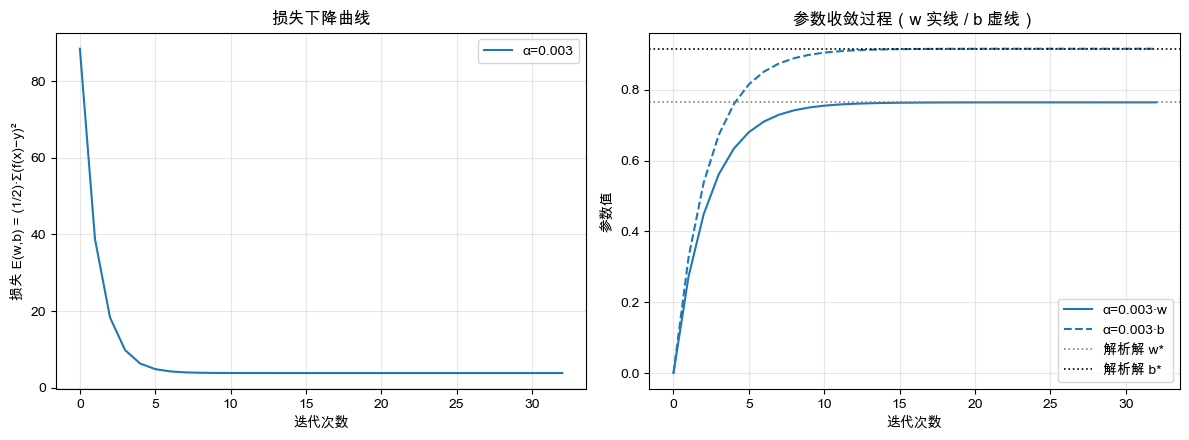

In [10]:
# 绘制损失、模型参数随迭代次数的变化曲线（封装成函数，支持对比多组训练结果）
import matplotlib.pyplot as plt

# 中文显示设置（macOS 字体）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']
plt.rcParams['axes.unicode_minus'] = False


def plot_gd_curves(histories, labels, w_star=None, b_star=None):
    """绘制梯度下降训练的损失曲线与参数收敛曲线。

    参数:
        histories: list，一个或多个训练记录（gradient_descent 返回的 history，
                   形状 (iters+1, 3)，每行 [损失E, w, b]，含第 0 点初始状态）
        labels:    list，与 histories 一一对应的标签（说明对应的超参数组）
        w_star / b_star: 可选，解析解 w、b，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        # 左图：损失 E 随迭代次数的变化（对应课件 p32 下图）
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        # 右图：参数收敛过程（w 实线、b 虚线，同色 = 同一组训练）
        ax2.plot(iters, h[:, 1], color=c, ls='-', label=f'{lab}·w')
        ax2.plot(iters, h[:, 2], color=c, ls='--', label=f'{lab}·b')

    if w_star is not None:
        ax2.axhline(w_star, color='gray', ls=':', lw=1.2, label='解析解 w*')
    if b_star is not None:
        ax2.axhline(b_star, color='black', ls=':', lw=1.2, label='解析解 b*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w,b) = (1/2)·Σ(f(x)−y)²')
    ax1.set_title('损失下降曲线')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数收敛过程（w 实线 / b 虚线）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：当前这组训练结果（之后调学习率时，把多组 history 一起传入即可对比）
plot_gd_curves([gd_history],
               [f'α={LEARNING_RATE}'],
               w_star=0.764369, b_star=0.915966)

### 调学习率观察收敛变化；

α=0.001  迭代  104 次 → w=0.764368, b=0.915965, E=3.816347
α=0.005  迭代   17 次 → w=0.764369, b=0.915966, E=3.816347
α=0.016  迭代  129 次 → w=0.764371, b=0.915968, E=3.816347


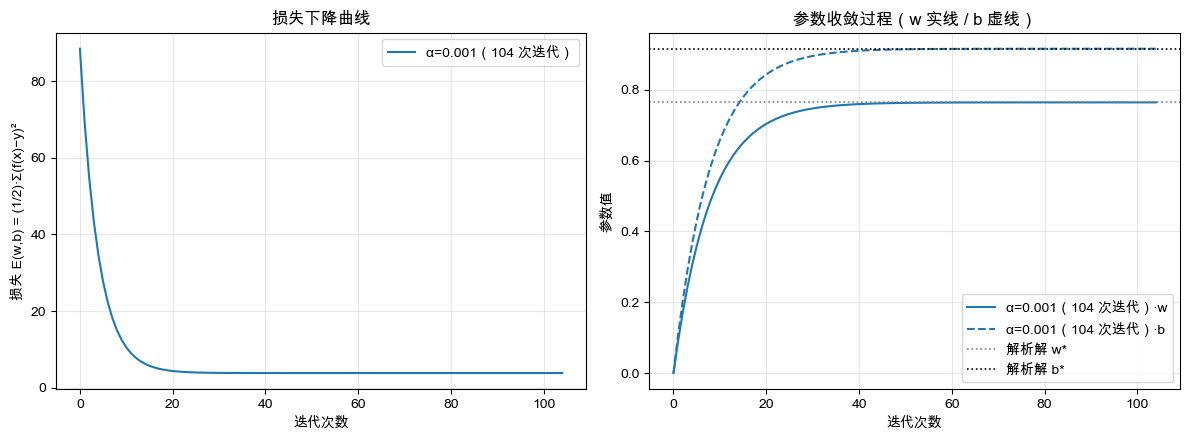

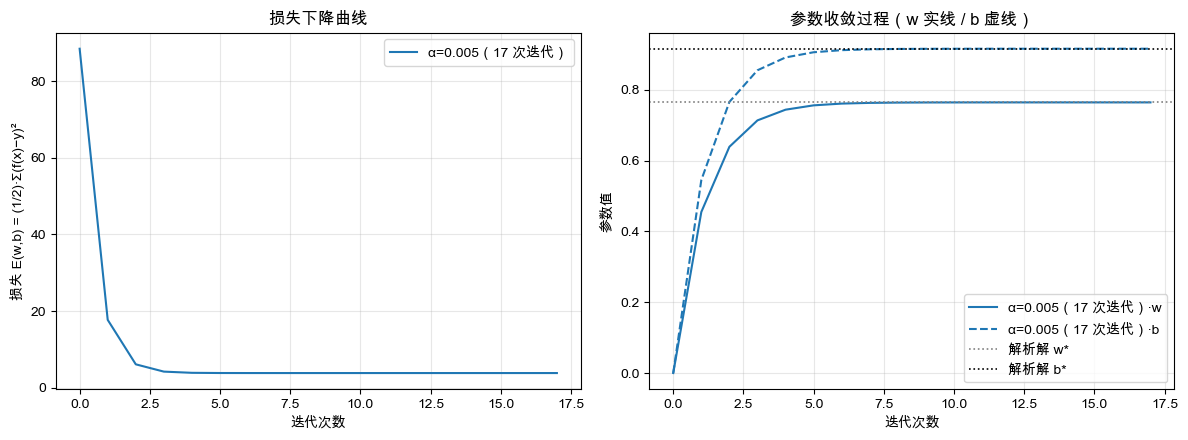

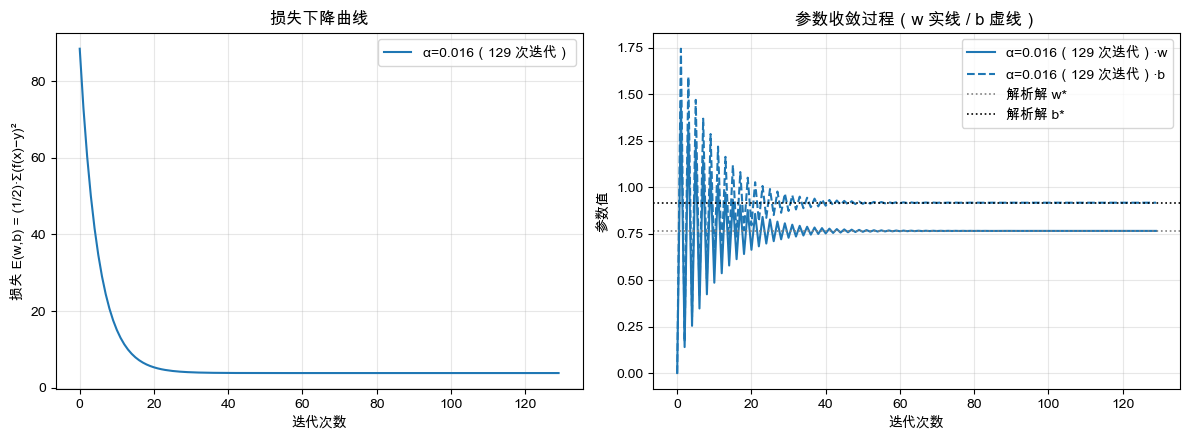

In [13]:
# 调学习率观察收敛变化：对比 3 组不同学习率 α 的训练过程
# 训练直接复用上一单元格的 gradient_descent，绘图直接复用 plot_gd_curves

# 三组学习率的设计（本任务稳定上界 ≈ 2/Σx² ≈ 0.0168）：
#   α=0.001 偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.005 适中 → 快速平稳收敛
#   α=0.016 偏大 → 逼近稳定上界，参数来回震荡后收敛（超过 0.0168 则发散，可自行验证）
learning_rates = [0.001, 0.005, 0.016]

histories, labels = [], []
for lr in learning_rates:
    w_lr, b_lr, h = gradient_descent(x, y, lr=lr)
    histories.append(h)
    labels.append(f'α={lr}（{len(h) - 1} 次迭代）')
    print(f'α={lr:<6} 迭代 {len(h) - 1:4d} 次 → w={w_lr:.6f}, b={b_lr:.6f}, E={h[-1, 0]:.6f}')

# 三组损失曲线 / 参数收敛曲线同图对比，虚线为解析解
plot_gd_curves([histories[0]], [labels[0]], w_star=0.764369, b_star=0.915966)
plot_gd_curves([histories[1]], [labels[1]], w_star=0.764369, b_star=0.915966)
plot_gd_curves([histories[2]], [labels[2]], w_star=0.764369, b_star=0.915966)

### 可视化：训练散点 + 拟合直线

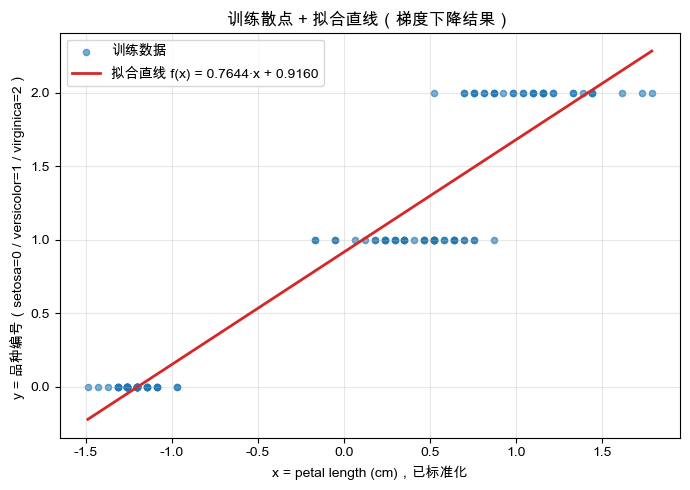

In [14]:
# 可视化：训练散点 + 拟合直线
# 使用最初始超参数（α=LEARNING_RATE=0.003）训练的 gd_history 的最终参数 w_gd, b_gd
# 对应课件《单变量-梯度下降法》p32 上图：预测函数（红线）+ 训练数据（散点）
import matplotlib.pyplot as plt

# 中文显示设置（macOS 字体）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']
plt.rcParams['axes.unicode_minus'] = False


def plot_fit_line(x, y, w, b):
    """绘制单变量线性回归的训练散点 + 拟合直线 f(x) = w·x + b。

    参数:
        x, y: 训练数据（形状 (m,)）
        w, b: 模型参数（梯度下降结果 w_gd, b_gd）
    """
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(x, y, s=20, alpha=0.6, color='tab:blue', label='训练数据')
    x_line = np.linspace(x.min(), x.max(), 100)        # 在 x 取值范围内取点画直线
    ax.plot(x_line, w * x_line + b, color='tab:red', lw=2,
            label=f'拟合直线 f(x) = {w:.4f}·x + {b:.4f}')

    ax.set_xlabel('x = petal length (cm)，已标准化')
    ax.set_ylabel('y = 品种编号（setosa=0 / versicolor=1 / virginica=2）')
    ax.set_title('训练散点 + 拟合直线（梯度下降结果）')
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# 调用：最初始超参数训练得到的参数
plot_fit_line(x, y, w_gd, b_gd)

# 2变量

## 解析解法

In [15]:
# 2变量线性回归 —— 解析解（严格按课件《多变量-解析解法》p33-39 以向量形式实现）
# 模型: y = w0·1 + w1·x1 + w2·x2 = w^T·x      （课件 p33：令 w0=b, x0=1）
# 损失: E(w) = (1/2)·||Xw − y||²               （课件 p37 矩阵形式）
# 正规方程: w = (X^T·X)^(-1)·X^T·y = X⁺·y      （课件 p39，凸函数梯度为零处）
import numpy as np

# ---------- 1 准备 2 变量数据（与单变量一节保持一致的目标值） ----------
# 两个特征: x1 = petal length, x2 = petal width（均已标准化）
# 目标值:   y = 品种编号（setosa=0, versicolor=1, virginica=2，沿用 y_train 映射）
y = y_train.map({'setosa': 0, 'versicolor': 1, 'virginica': 2}).to_numpy()
m = len(y)                                            # 训练样本数
X0 = x_train[['petal length (cm)', 'petal width (cm)']].to_numpy()   # (m, 2)

# ---------- 2 构造设计矩阵 X：每行一个样本，首列补 1（课件 p36） ----------
X = np.hstack([np.ones((m, 1)), X0])                  # (m, 3)

# ---------- 3 正规方程求解析解 w = (X^T·X)^(-1)·X^T·y ----------
w_vec = np.linalg.inv(X.T @ X) @ X.T @ y              # (3,) = [b, w1, w2]

# ---------- 4 拆分参数并计算损失 ----------
b2, w1, w2 = w_vec[0], w_vec[1], w_vec[2]             # w[0] 即偏置 b
E = np.sum((X @ w_vec - y) ** 2) / 2                  # E = (1/2)·||Xw − y||²

print(f'样本数 m        = {m}')
print(f'解析解 b (w0)   = {b2:.6f}')
print(f'解析解 w1 (长度) = {w1:.6f}')
print(f'解析解 w2 (宽度) = {w2:.6f}')
print(f'损失 E(1/2·Σ)   = {E:.6f}')
print(f'损失 E(1/2m·Σ)  = {E / (2 * m):.6f}  (单变量解析解为 0.032070，加入 w2 后更小)')
print(f'(对照 np.linalg.lstsq: {np.allclose(w_vec, np.linalg.lstsq(X, y, rcond=None)[0])})')

样本数 m        = 119
解析解 b (w0)   = 0.915966
解析解 w1 (长度) = 0.225171
解析解 w2 (宽度) = 0.554436
损失 E(1/2·Σ)   = 2.824762
损失 E(1/2m·Σ)  = 0.011869  (单变量解析解为 0.032070，加入 w2 后更小)
(对照 np.linalg.lstsq: True)


## 梯度下降法

### 绘制损失、模型参数随迭代次数的变化曲线

迭代次数      = 847
梯度下降 w    = [0.915966 0.22521  0.554398]   （w0 即偏置 b）
最终损失 E    = 2.824762
(对照解析解   = [0.915966 0.225171 0.554436])


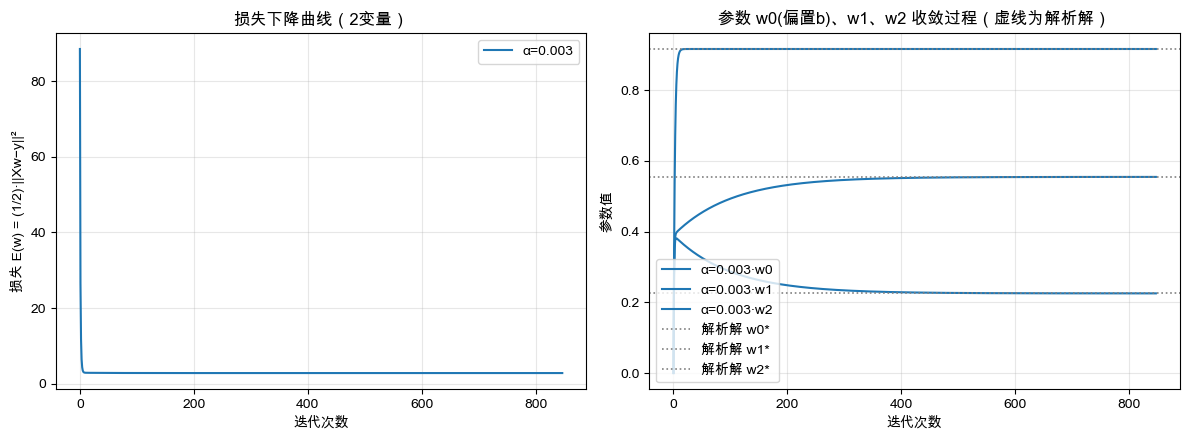

In [18]:
# 2变量线性回归 —— 梯度下降法（严格按课件《多变量-梯度下降法》p40，向量形式实现）
# 更新规则（批量梯度下降，与解析解共用上面的设计矩阵 X、目标值 y）：
#   w := w − α·X^T·(Xw − y)        —— 课件 p40 的 w_j := w_j − α·Σ(f(x_i)−y_i)·x_ij 的向量形式，
#                                       整个参数向量一次赋值，天然满足"同时更新 w_j, j=0,1,…,n"
# 损失函数（课件 p40，系数 1/2）：E(w) = (1/2)·||Xw − y||²
import numpy as np
import matplotlib.pyplot as plt

# ==================== 超参数与停止阈值（集中定义，便于统一调整） ====================
LEARNING_RATE_2V = 0.003   # 学习率 α（稳定上界 2/λmax(XᵀX) ≈ 0.0085，因花瓣长/宽强相关 λmax≈235）
MAX_ITERS_2V     = 5000    # 最大迭代次数
TOL_2V           = 1e-10   # 停止阈值：相邻两次损失变化 < TOL 即认为已收敛
W_INIT_2V        = None    # 起始点 w 向量（None = 零向量 [0, 0, 0]）


# ==================== 梯度下降主体（向量形式） ====================
def gradient_descent_vec(X, y, lr=LEARNING_RATE_2V, max_iter=MAX_ITERS_2V, tol=TOL_2V,
                         w=None):
    """向量形式批量梯度下降求解多变量线性回归。

    返回: (w, history)
        history: (iters+1, n+2) 数组，每行是 [损失E, w0, w1, w2]，
                 含第 0 次迭代前的初始状态，供绘制损失/参数变化曲线。
    """
    w = np.zeros(X.shape[1]) if w is None else w.copy()
    history = [(np.sum((X @ w - y) ** 2) / 2, *w)]        # 记录初始状态
    for t in range(max_iter):
        w = w - lr * (X.T @ (X @ w - y))                  # 同步更新（一次向量运算）
        history.append((np.sum((X @ w - y) ** 2) / 2, *w))
        if abs(history[-2][0] - history[-1][0]) < tol:    # 损失几乎不再下降 → 停止
            break
    return w, np.array(history)


def plot_gd_curves_n(histories, labels, w_star=None):
    """绘制多变量梯度下降的损失曲线与各参数收敛曲线（plot_gd_curves 的多变量推广版）。

    参数:
        histories: list，训练记录（gradient_descent_vec 返回的 history，
                   每行 [损失E, w0, w1, …, wn]）
        labels:    list，与 histories 一一对应的标签
        w_star:    可选，解析解参数向量，用于画对照虚线
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

    for h, lab, c in zip(histories, labels, colors):
        iters = np.arange(len(h))
        ax1.plot(iters, h[:, 0], color=c, label=lab)
        for j in range(h.shape[1] - 1):                   # 逐个参数画收敛曲线
            ax2.plot(iters, h[:, j + 1], color=c, label=f'{lab}·w{j}')

    if w_star is not None:                                # 解析解对照（虚线）
        for j, ws in enumerate(np.atleast_1d(w_star)):
            ax2.axhline(ws, color='gray', ls=':', lw=1.2, label=f'解析解 w{j}*')

    ax1.set_xlabel('迭代次数')
    ax1.set_ylabel('损失 E(w) = (1/2)·||Xw−y||²')
    ax1.set_title('损失下降曲线（2变量）')
    ax1.legend()
    ax1.grid(alpha=0.3)

    ax2.set_xlabel('迭代次数')
    ax2.set_ylabel('参数值')
    ax2.set_title('参数 w0(偏置b)、w1、w2 收敛过程（虚线为解析解）')
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


# ==================== 运行（沿用解析解单元格的 X、y，结果直接对应） ====================
w_gd_vec, gd_hist_vec = gradient_descent_vec(X, y)

print(f'迭代次数      = {len(gd_hist_vec) - 1}')
print(f'梯度下降 w    = {w_gd_vec.round(6)}   （w0 即偏置 b）')
print(f'最终损失 E    = {gd_hist_vec[-1, 0]:.6f}')
print(f'(对照解析解   = {w_vec.round(6)})')

plot_gd_curves_n([gd_hist_vec], [f'α={LEARNING_RATE_2V}'], w_star=w_vec)

### 调学习率观察收敛变化；

=== α = 0.001 ===
迭代次数   = 2378
梯度下降 w = [0.915966 0.225239 0.554368]
最终损失 E = 2.824762
(对照解析解 = [0.915966 0.225171 0.554436])



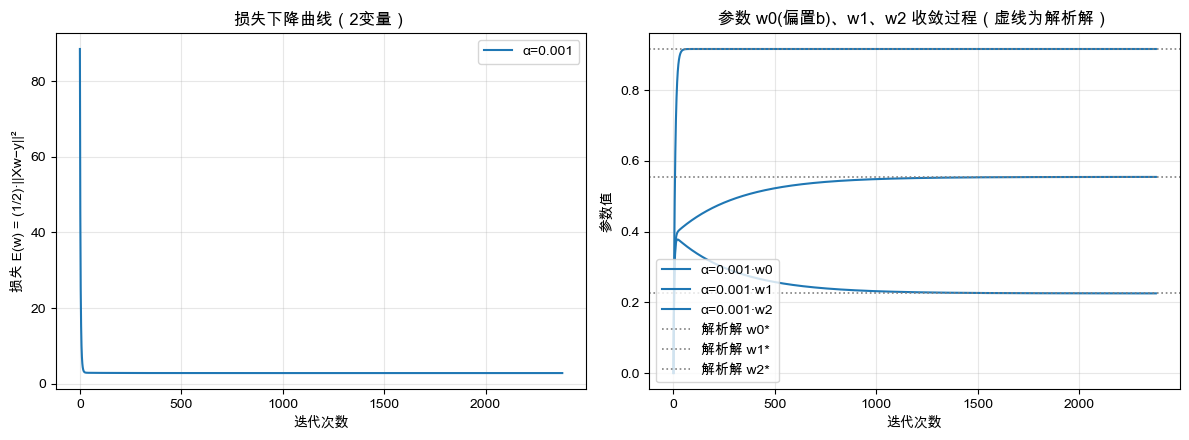

=== α = 0.003 ===
迭代次数   = 847
梯度下降 w = [0.915966 0.22521  0.554398]
最终损失 E = 2.824762
(对照解析解 = [0.915966 0.225171 0.554436])



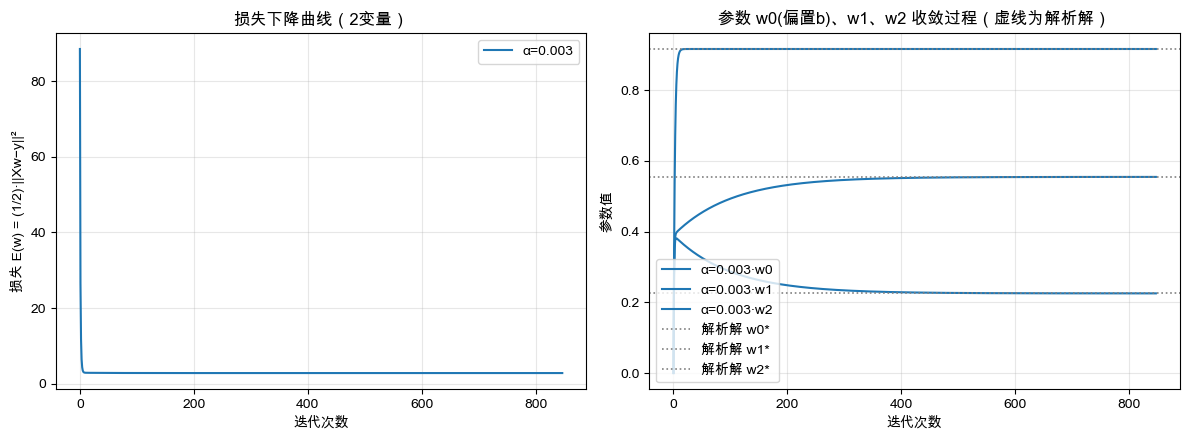

=== α = 0.008 ===
迭代次数   = 334
梯度下降 w = [0.915966 0.225195 0.554413]
最终损失 E = 2.824762
(对照解析解 = [0.915966 0.225171 0.554436])



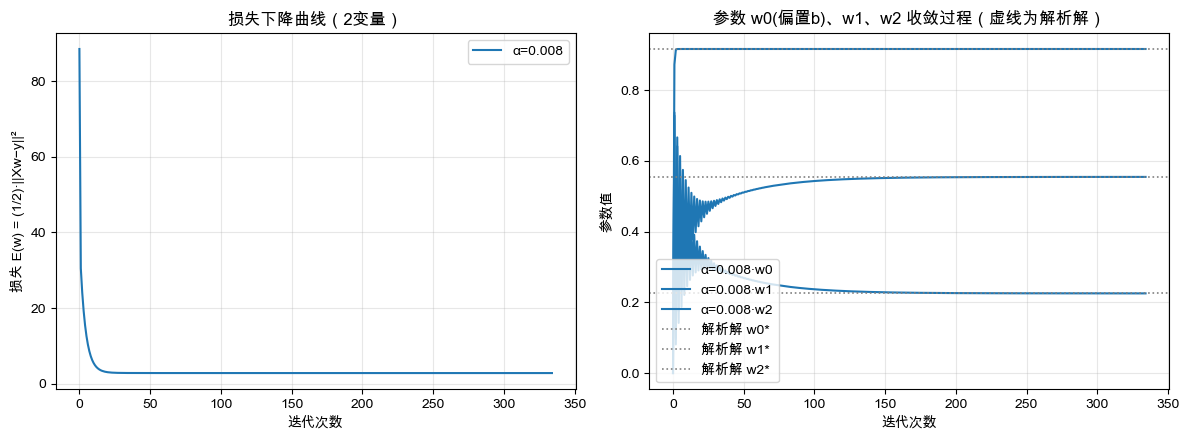

In [19]:
# 调学习率观察收敛变化（2变量）：对比 3 组不同学习率 α，分三次训练并分别输出
# 训练复用上一单元格的 gradient_descent_vec，绘图复用 plot_gd_curves_n（参考单变量的方式）
#
# 三组学习率的设计（本任务稳定上界 2/λmax(XᵀX) ≈ 0.0085）：
#   α=0.001 偏小 → 每步挪得少，收敛慢、曲线平滑
#   α=0.003 适中 → 平稳收敛（默认值）
#   α=0.008 偏大 → 接近稳定上界，参数来回震荡后收敛（超过 0.0085 则发散，可自行验证）
learning_rates_2v = [0.001, 0.003, 0.008]

for lr in learning_rates_2v:
    # ---- 训练一组学习率 ----
    w_lr, h_lr = gradient_descent_vec(X, y, lr=lr)

    # ---- 打印该组结果 ----
    print(f'=== α = {lr} ===')
    print(f'迭代次数   = {len(h_lr) - 1}')
    print(f'梯度下降 w = {w_lr.round(6)}')
    print(f'最终损失 E = {h_lr[-1, 0]:.6f}')
    print(f'(对照解析解 = {w_vec.round(6)})\n')

    # ---- 单独绘制该组的损失/参数收敛曲线（分三次输出） ----
    plot_gd_curves_n([h_lr], [f'α={lr}'], w_star=w_vec)

### 可视化：训练散点 + 拟合平面

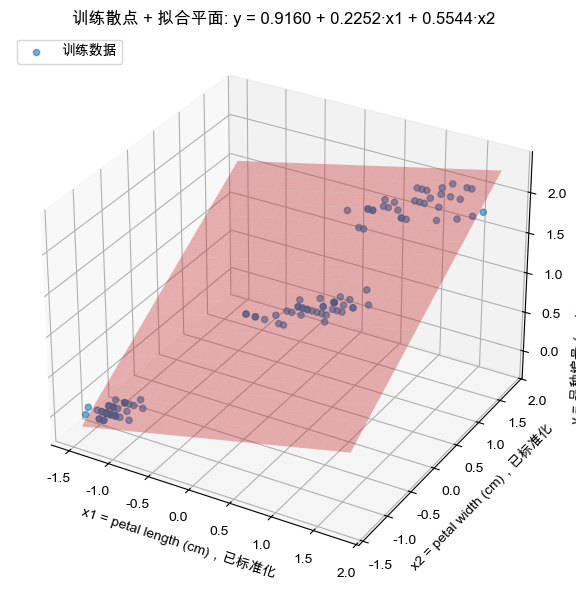

In [20]:
# 可视化：训练散点 + 拟合平面（2变量线性回归，三维图）
# 使用默认超参数（α=LEARNING_RATE_2V=0.003）训练的 w_gd_vec，与解析解几乎一致
# 拟合平面: y = w0 + w1·x1 + w2·x2
import matplotlib.pyplot as plt

# 中文显示设置（macOS 字体）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'PingFang SC', 'Hiragino Sans GB']
plt.rcParams['axes.unicode_minus'] = False


def plot_fit_plane(X0, y, w):
    """绘制 2 变量线性回归的训练散点 + 拟合平面（3D 图）。

    参数:
        X0: (m, 2) 两个特征的原始数据（不含 1 列）
        y:  (m,)   目标值
        w:  (3,)   模型参数 [w0(偏置b), w1, w2]（梯度下降结果 w_gd_vec）
    """
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(projection='3d')

    # 训练散点
    ax.scatter(X0[:, 0], X0[:, 1], y, s=20, alpha=0.6,
               color='tab:blue', label='训练数据')

    # 拟合平面：在两特征的取值范围内铺网格，按模型计算 z
    g1 = np.linspace(X0[:, 0].min(), X0[:, 0].max(), 20)
    g2 = np.linspace(X0[:, 1].min(), X0[:, 1].max(), 20)
    G1, G2 = np.meshgrid(g1, g2)
    ax.plot_surface(G1, G2, w[0] + w[1] * G1 + w[2] * G2,
                    alpha=0.35, color='tab:red')

    ax.set_xlabel('x1 = petal length (cm)，已标准化')
    ax.set_ylabel('x2 = petal width (cm)，已标准化')
    ax.set_zlabel('y = 品种编号（setosa=0 / versicolor=1 / virginica=2）')
    ax.set_title(f'训练散点 + 拟合平面: y = {w[0]:.4f} + {w[1]:.4f}·x1 + {w[2]:.4f}·x2')
    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# 调用：默认超参数训练得到的参数
plot_fit_plane(X0, y, w_gd_vec)